# Figure 1 — Scene previews speed face detection

**b, c** Detection latency per participant, preview versus no preview.
**d, e** Per-image mean latency in the two conditions.

Detection latency is the onset of the last fixation of the trial, measured from
search-display onset; the display was gaze-contingent and ended when the observer
fixated the face. Fixations beginning within 100 ms of onset are discarded and
timeout trials are dropped. Panels b and c show raw means; the statistics are
computed on log latency, because latencies are right-skewed and multiplicative.

Panels d and e regress the **paired** per-image means, so a point's x and y
coordinates come from the same scene. Note that independently sorting the two
vectors would turn this into a quantile-quantile plot and break the pairing.

In [1]:
import sys
from pathlib import Path

# The notebooks live next to the code, so the package is importable without
# installing anything. Nothing outside this release is referenced.
sys.path.insert(0, str(Path.cwd().parent / "code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from facescenes import config as cfg
from facescenes import data as D
from facescenes import behaviour as B
from facescenes import encoding as E
from facescenes import onset_gaze as G
from facescenes import plotting as P
from facescenes import stats as S

P.use_style()
print("stimuli    :", len(D.stimulus_names()))
for t in cfg.TASKS:
    print(f"{t:14s}: {len(D.participant_ids(t))} participants, "
          f"{len(D.analysable_images(t))} images")

stimuli    : 120


facedetection : 38 participants, 108 images


movingwindow  : 38 participants, 120 images


## b, c — detection latency per participant

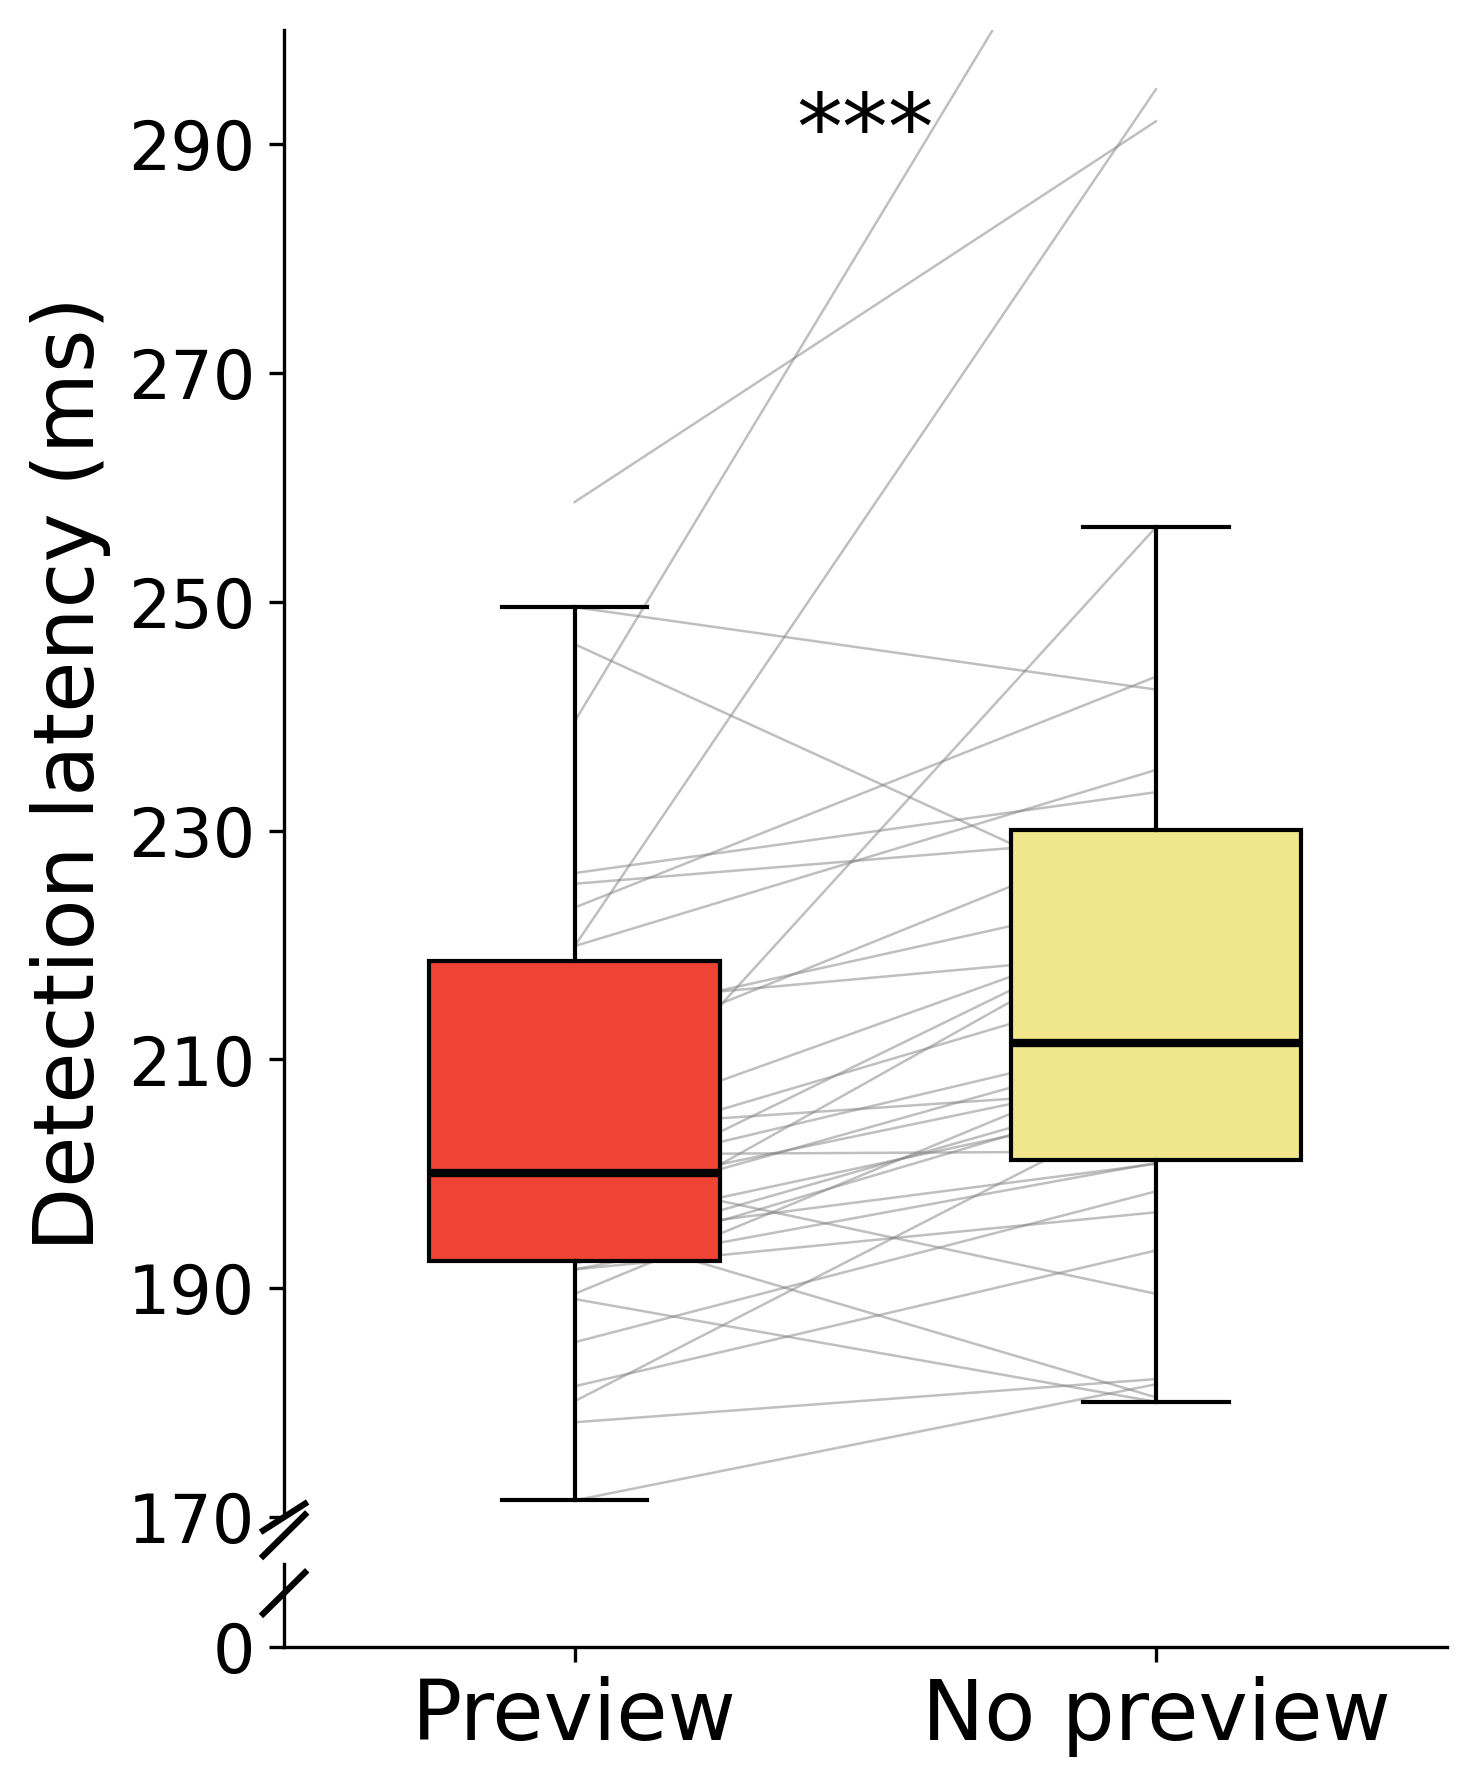

Face detection task
  raw means       208.8 vs 221.7 ms
  geometric means 198.8 vs 208.3 ms (-4.53 %)
  test on log:    t(37) = -4.136, p = 0.0001952, dz = -0.67, 95% CI [-1.00, -0.34]


In [2]:
def panel_latency(task, fname, step, resume=None, ylim=None):
    df = B.trial_table(task)
    a, b = B.participant_means(df, "latency_ms")
    r = B.detection_latency(task)

    lo = 0 if resume is None else resume
    hi = ylim if ylim else np.ceil(max(np.nanmax(a), np.nanmax(b)) / step) * step

    if resume is None:
        fig, ax = plt.subplots(figsize=(5, 7))
        stub = None
    else:
        # The axis has to start at zero, and the effect is a few ms on a mean of
        # ~200 ms, so the axis is broken: a stub carrying the zero tick, the
        # break, then the data range from `resume` up.
        fig, (ax, stub) = plt.subplots(2, 1, sharex=True, figsize=(5, 7),
                                       gridspec_kw=dict(height_ratios=[18, 1],
                                                        hspace=.06))

    for a_ in ([ax] if stub is None else [ax, stub]):
        for i in range(len(a)):
            a_.plot([0, 1], [a[i], b[i]], color="grey", lw=.6, alpha=.5, zorder=1)
        box = a_.boxplot([a, b], positions=[0, 1], widths=.5, patch_artist=True,
                         showfliers=False, zorder=2,
                         medianprops=dict(color="k", lw=2))
        for patch, cond in zip(box["boxes"], cfg.CONDITIONS):
            patch.set_facecolor(P.condition_colours()[cond])
            patch.set_edgecolor("k")
        P.clean(a_)

    ax.set_ylim(lo, hi)
    ax.set_yticks(np.arange(lo, hi + step / 2, step))
    ax.set_xticks([0, 1])
    ax.tick_params(axis="y", labelsize=P.FONT - 12)   # as in Fig. 1d/e
    P.title(ax, cfg.TASK_LABEL[task], fontsize=P.FONT - 6, pad=12)
    ax.text(.5, .96, P.significance(r["p"]), ha="center", va="top",
            transform=ax.transAxes, fontsize=P.FONT - 6)
    ax.set_ylabel("Detection latency (ms)", fontsize=P.FONT - 8)
    labels = [cfg.COND_LABEL[c] for c in cfg.CONDITIONS]

    if stub is None:
        ax.set_xticklabels(labels, fontsize=P.FONT - 8)
    else:
        stub.set_ylim(0, lo * .04)          # a sliver of the axis, so 0 is shown
        stub.set_yticks([0])
        stub.tick_params(axis="y", labelsize=P.FONT - 12)
        stub.set_xticklabels(labels, fontsize=P.FONT - 8)
        ax.spines["bottom"].set_visible(False)
        stub.spines["top"].set_visible(False)
        ax.tick_params(axis="x", bottom=False)
        P.break_marker(ax, stub)
    src = B.participant_table(df, "latency_ms").rename(
        columns=lambda c: f"{c}_mean_latency_ms").reset_index()
    P.save(fig, fname, src); plt.show()

    print(f"{cfg.TASK_LABEL[task]}")
    print(f"  raw means       {r['mean_a']:.1f} vs {r['mean_b']:.1f} ms")
    print(f"  geometric means {r['geo_a']:.1f} vs {r['geo_b']:.1f} ms "
          f"({r['pct_change']:+.2f} %)")
    print(f"  test on log:    t({r['n']-1}) = {r['t']:.3f}, p = {r['p']:.4g}, "
          f"dz = {r['dz']:.2f}, 95% CI [{r['dz_ci'][0]:.2f}, {r['dz_ci'][1]:.2f}]")


panel_latency("facedetection", "fig1b_latency_face_detection.png",
              step=20, resume=170, ylim=300)

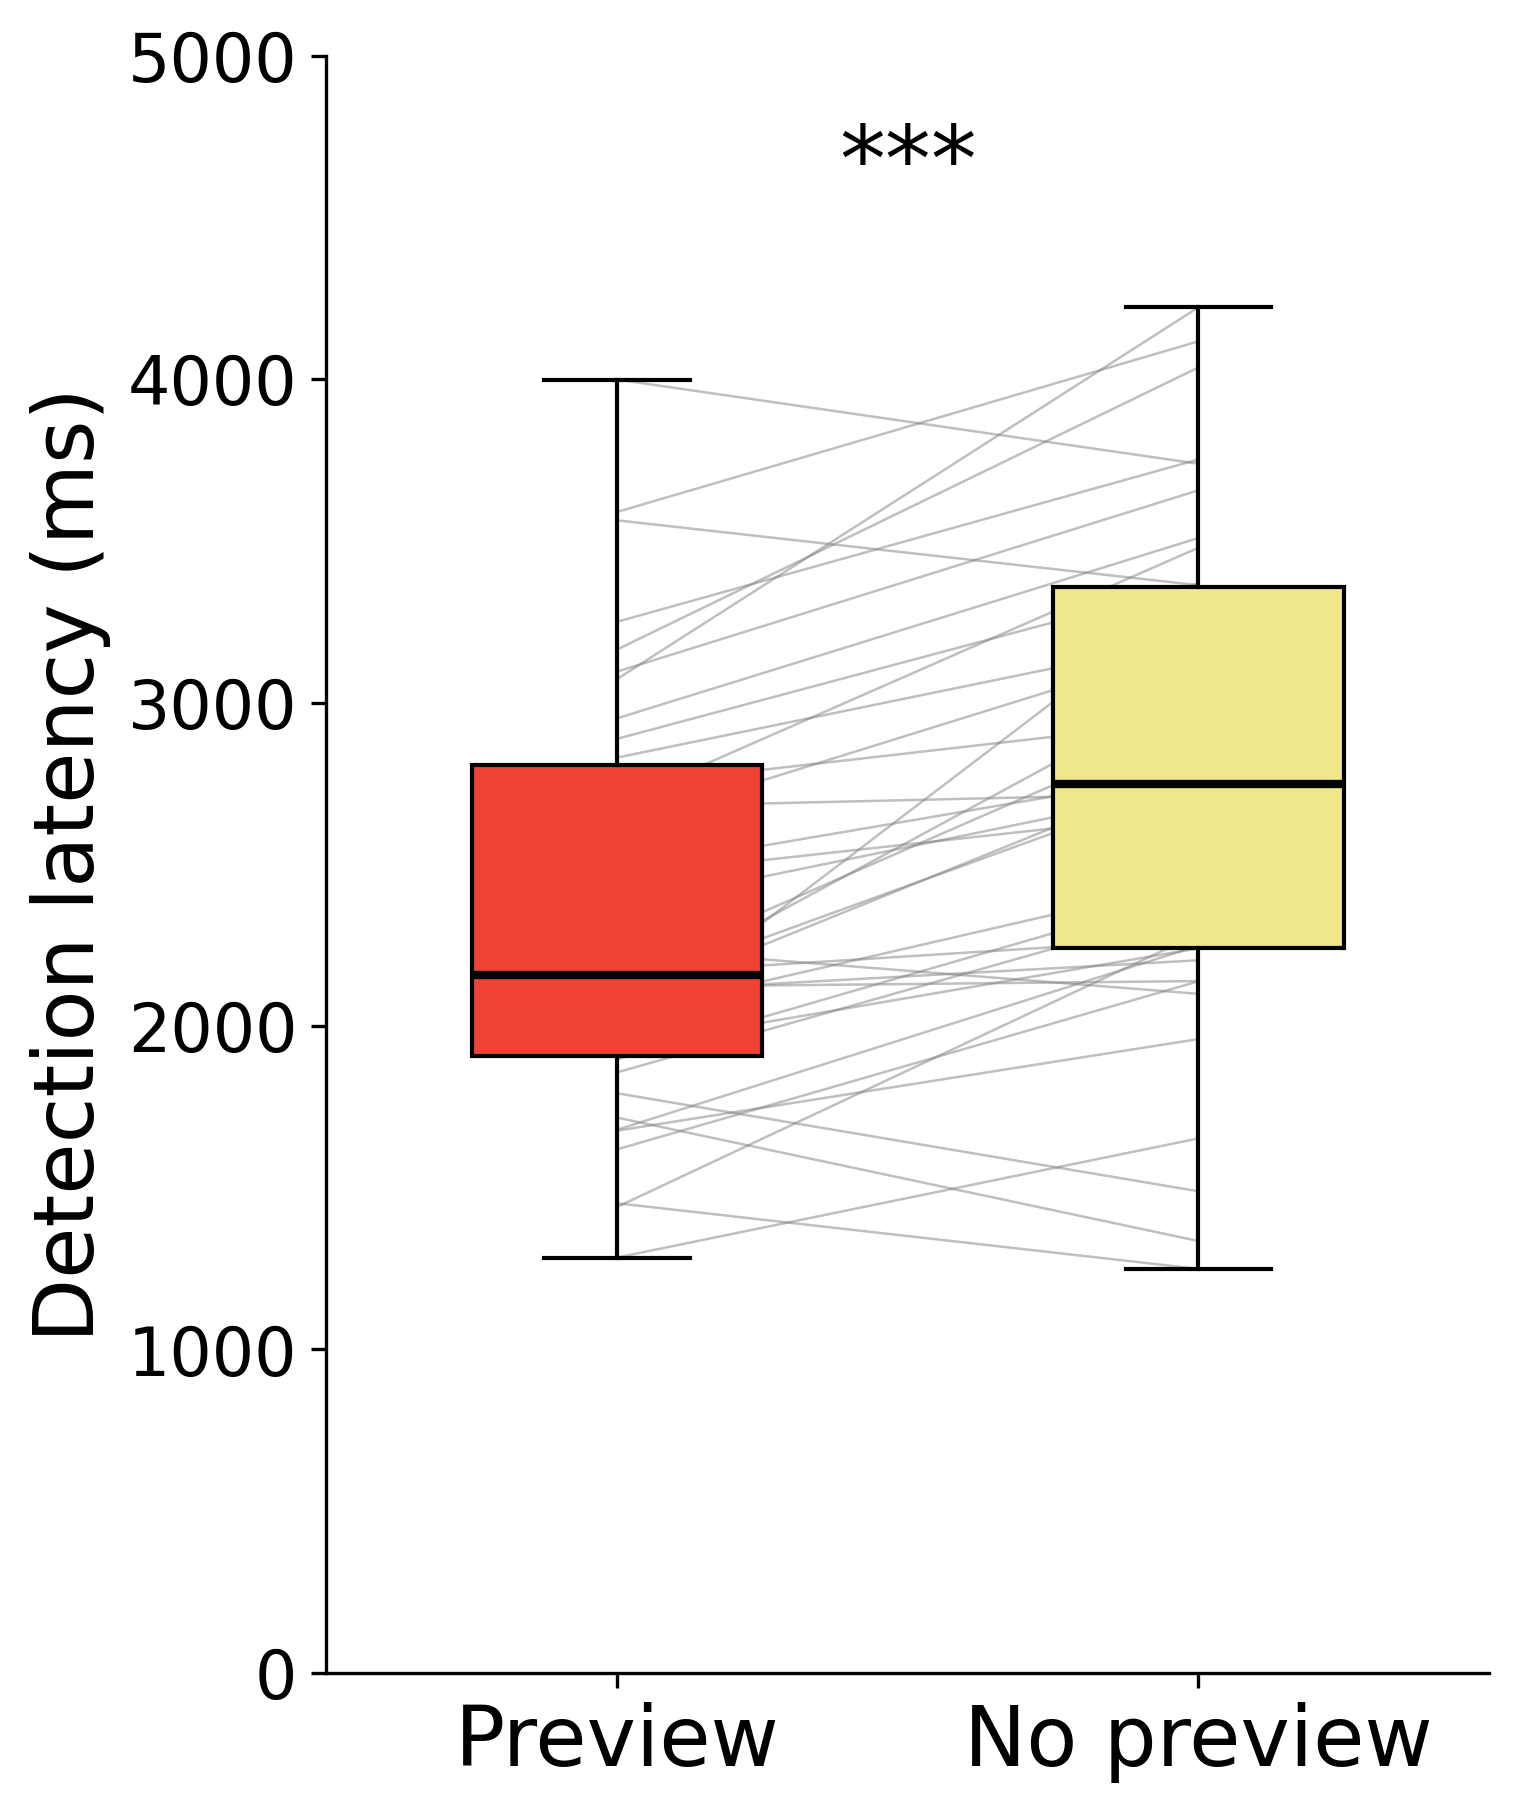

Moving-window task
  raw means       2364.3 vs 2760.7 ms
  geometric means 1662.8 vs 1986.9 ms (-16.31 %)
  test on log:    t(37) = -7.961, p = 1.547e-09, dz = -1.29, 95% CI [-1.62, -0.96]


In [3]:
panel_latency("movingwindow", "fig1c_latency_moving_window.png", step=1000)

## d, e — per-image latency, preview against no preview

Each point is one image's **geometric mean** latency in the two conditions: the
mean of the log latencies, the same per-image quantity the encoding models
predict and the reliabilities are computed on. The axes are logarithmic and the
line is a least-squares fit in log space, so a slope below 1 means preview
shortens slow images by a larger *proportion* than fast ones.

R² is compared with a ceiling equal to the product of the two conditions'
Pearson split-half reliabilities on this same scale (config.R2_CEILING).

The slope is tested against 1. Because no-preview latency is itself measured with
error, least squares attenuates the slope: a *true* slope of 1 would be observed
as roughly the reliability of the x variable. The disattenuated slope and that
benchmark are both reported, so the compression is not read off an artefact.

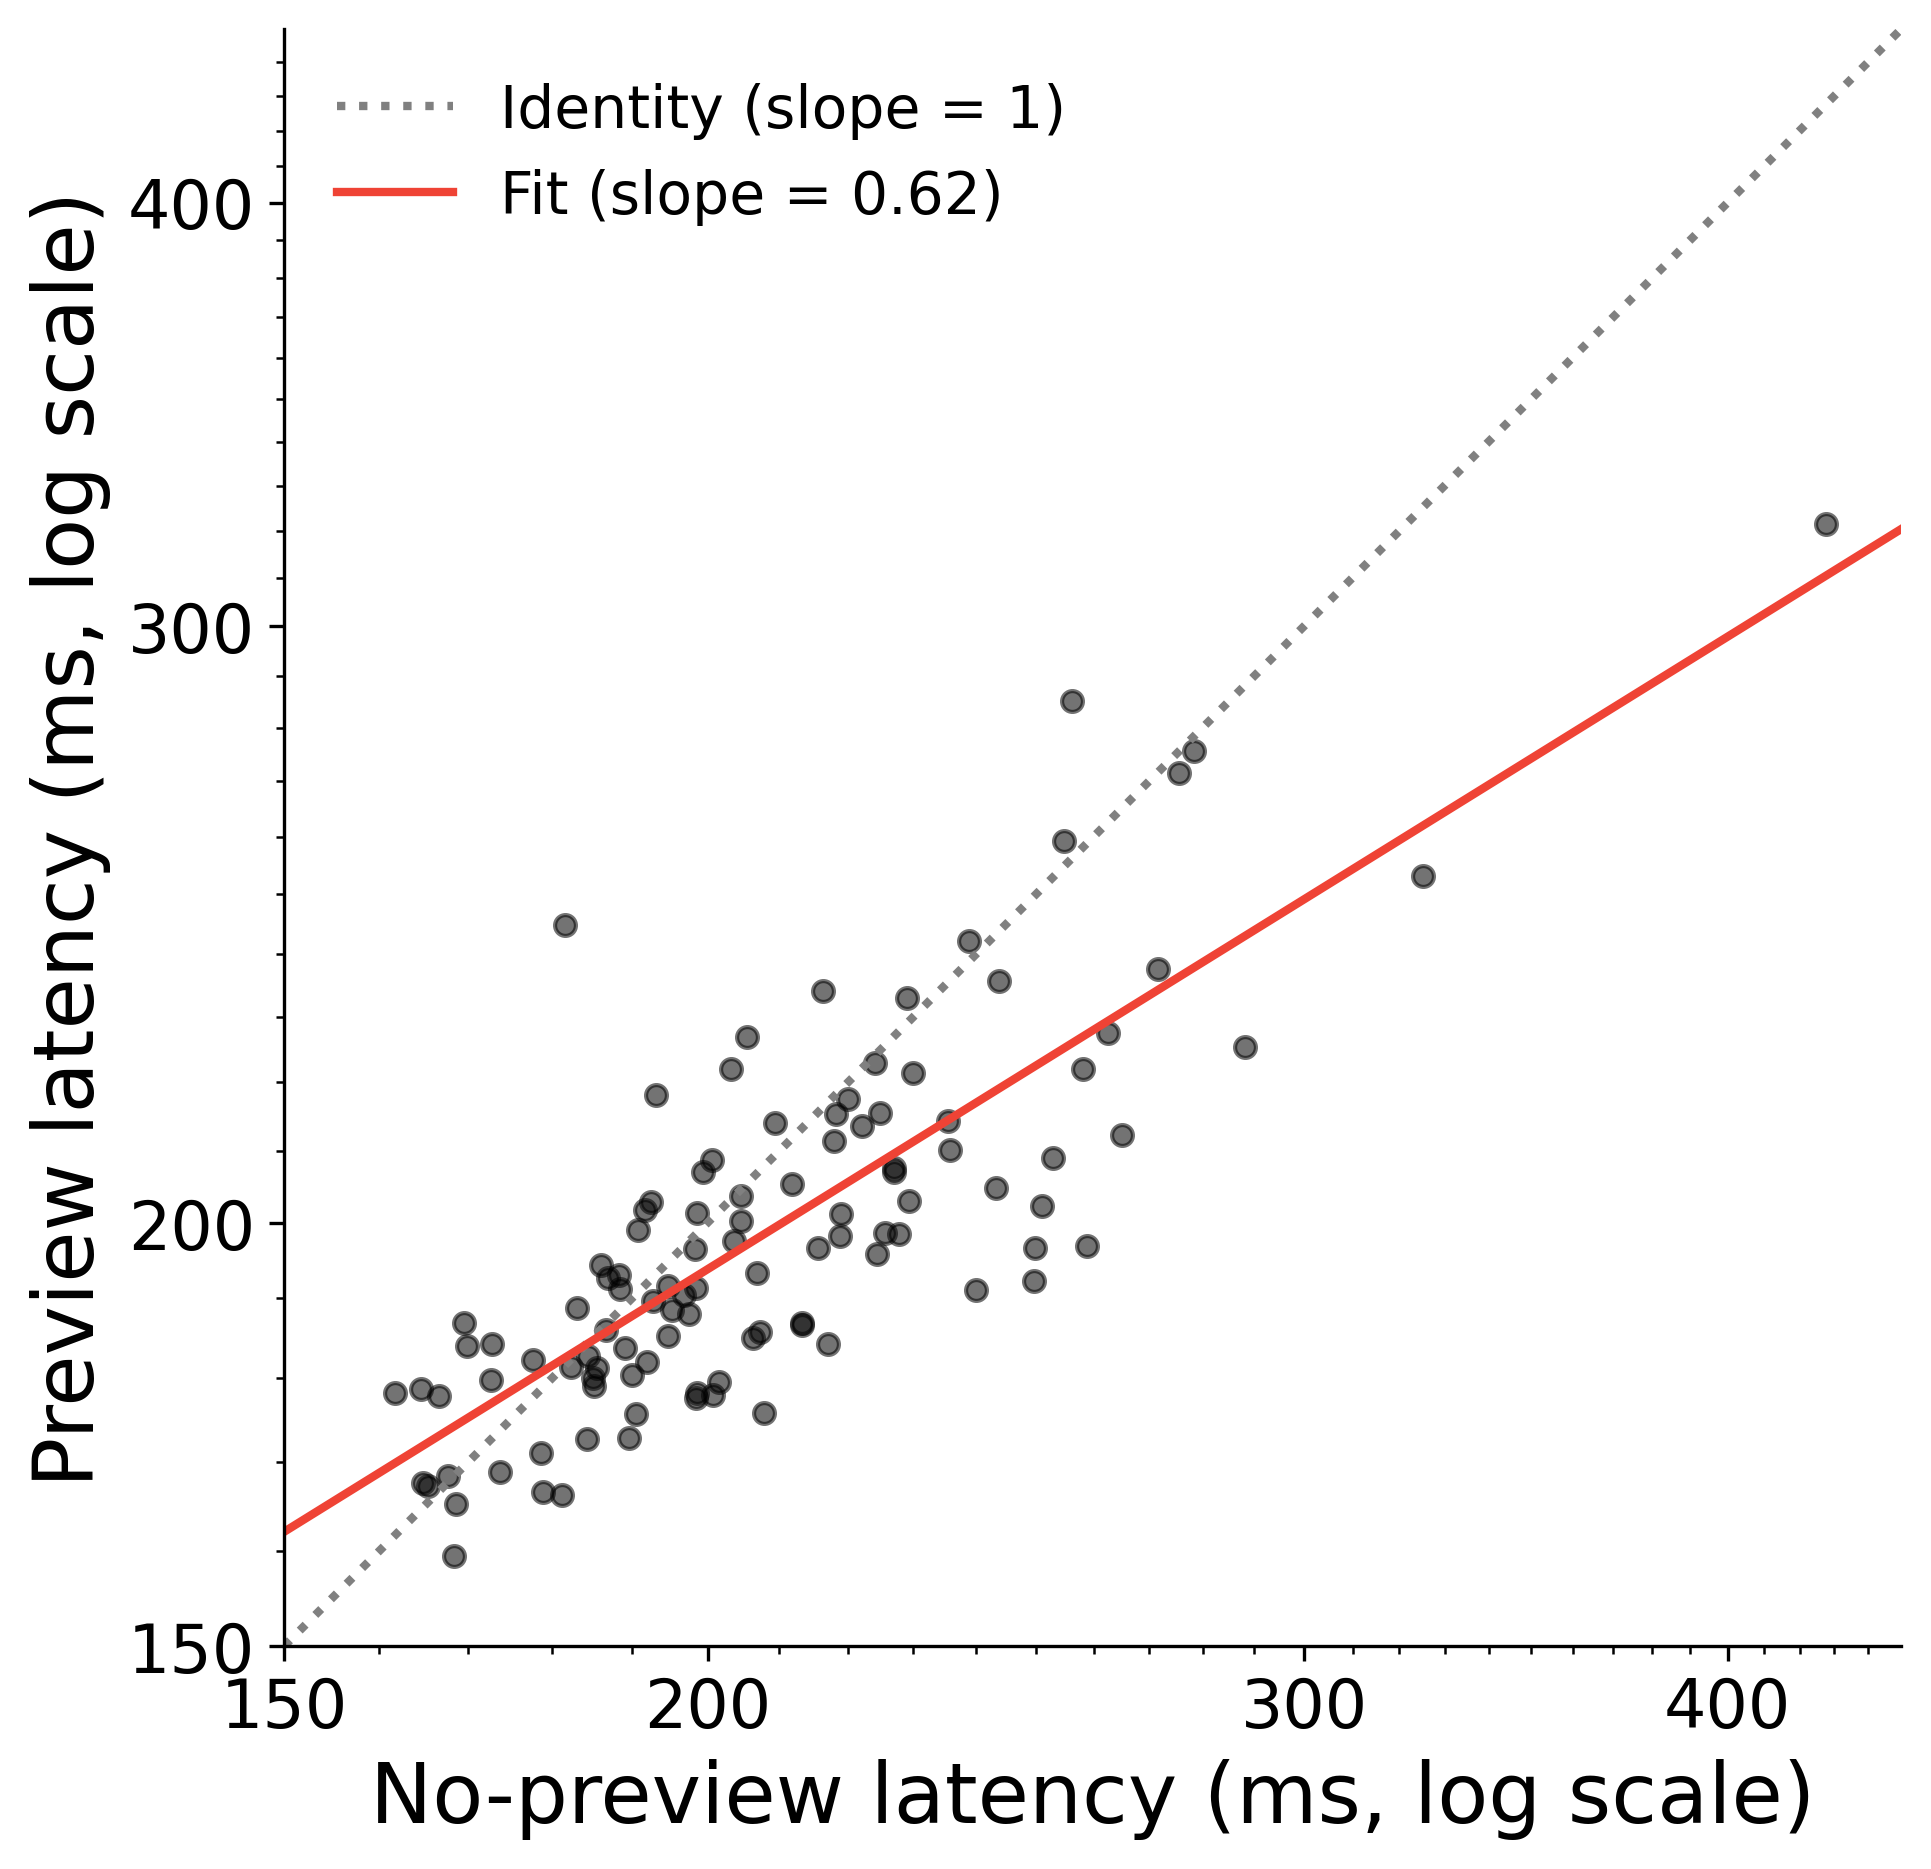

Face detection task   n = 108 images, log-scale geometric means
  R2        0.623      ceiling 0.671
  slope     0.620, 95% CI [0.513, 0.714]
  p(slope >= 1)                    9.999e-05
  attenuation benchmark            0.860  (a true slope of 1 reads as this)
  p(slope >= benchmark)            9.999e-05
  disattenuated slope              0.721
  images below the identity line   70 %


In [4]:
def panel_scatter(task, fname, ticks, lim, minor):
    lm = D.image_means(task, log=True)          # mean of log seconds
    keep = D.analysable_images(task)
    lx = lm[1, keep] + np.log(1000)              # no preview, log ms
    ly = lm[0, keep] + np.log(1000)              # preview, log ms
    x, y = np.exp(lx), np.exp(ly)                # geometric means, ms

    lr = stats.linregress(lx, ly)
    rng = np.random.default_rng(0)
    boot = np.array([stats.linregress(*(lambda i: (lx[i], ly[i]))(
        rng.integers(0, len(lx), len(lx)))).slope for _ in range(10000)])
    ci = np.percentile(boot, [2.5, 97.5])
    rel_x = cfg.RELIABILITY_PEARSON[task]["no_preview"]

    lo, hi = lim
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.plot([lo, hi], [lo, hi], ":", color="grey", lw=2, label="Identity (slope = 1)")
    ax.scatter(x, y, s=25, color="k", alpha=.55)
    gx = np.array([lo, hi])
    ax.plot(gx, np.exp(lr.intercept + lr.slope * np.log(gx)),
            color=cfg.C_PREVIEW, lw=2, label=f"Fit (slope = {lr.slope:.2f})")
    P.clean(ax)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks]); ax.set_yticklabels([str(t) for t in ticks])
    # log axes: conventional tick values whose uneven spacing shows the scale,
    # plus unlabelled minor ticks
    ax.set_xticks(minor, minor=True); ax.set_yticks(minor, minor=True)
    ax.set_xticklabels([], minor=True); ax.set_yticklabels([], minor=True)
    ax.tick_params(labelsize=P.FONT - 12)
    ax.set_xlabel("No-preview latency (ms, log scale)", fontsize=P.FONT - 8)
    ax.set_ylabel("Preview latency (ms, log scale)", fontsize=P.FONT - 8)
    P.title(ax, cfg.TASK_LABEL[task], fontsize=P.FONT - 6, pad=12)
    ax.legend(fontsize=P.FONT - 14, frameon=False, loc="upper left")
    src = pd.DataFrame({"image": np.asarray(D.stimulus_names())[keep],
                        "preview_geometric_mean_ms": y,
                        "no_preview_geometric_mean_ms": x})
    P.save(fig, fname, src); plt.show()

    print(f"{cfg.TASK_LABEL[task]}   n = {len(x)} images, log-scale geometric means")
    print(f"  R2        {lr.rvalue ** 2:.3f}      ceiling {cfg.R2_CEILING[task]:.3f}")
    print(f"  slope     {lr.slope:.3f}, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")
    print(f"  p(slope >= 1)                    {S.permutation_p(0, boot - 1, 'greater'):.4g}")
    print(f"  attenuation benchmark            {rel_x:.3f}  "
          f"(a true slope of 1 reads as this)")
    print(f"  p(slope >= benchmark)            "
          f"{S.permutation_p(0, boot - rel_x, 'greater'):.4g}")
    print(f"  disattenuated slope              {lr.slope / rel_x:.3f}")
    print(f"  images below the identity line   {100 * np.mean(y < x):.0f} %")


panel_scatter("facedetection", "fig1d_scatter_face_detection.png",
              ticks=[150, 200, 300, 400], lim=(150, 450),
              minor=range(160, 450, 10))

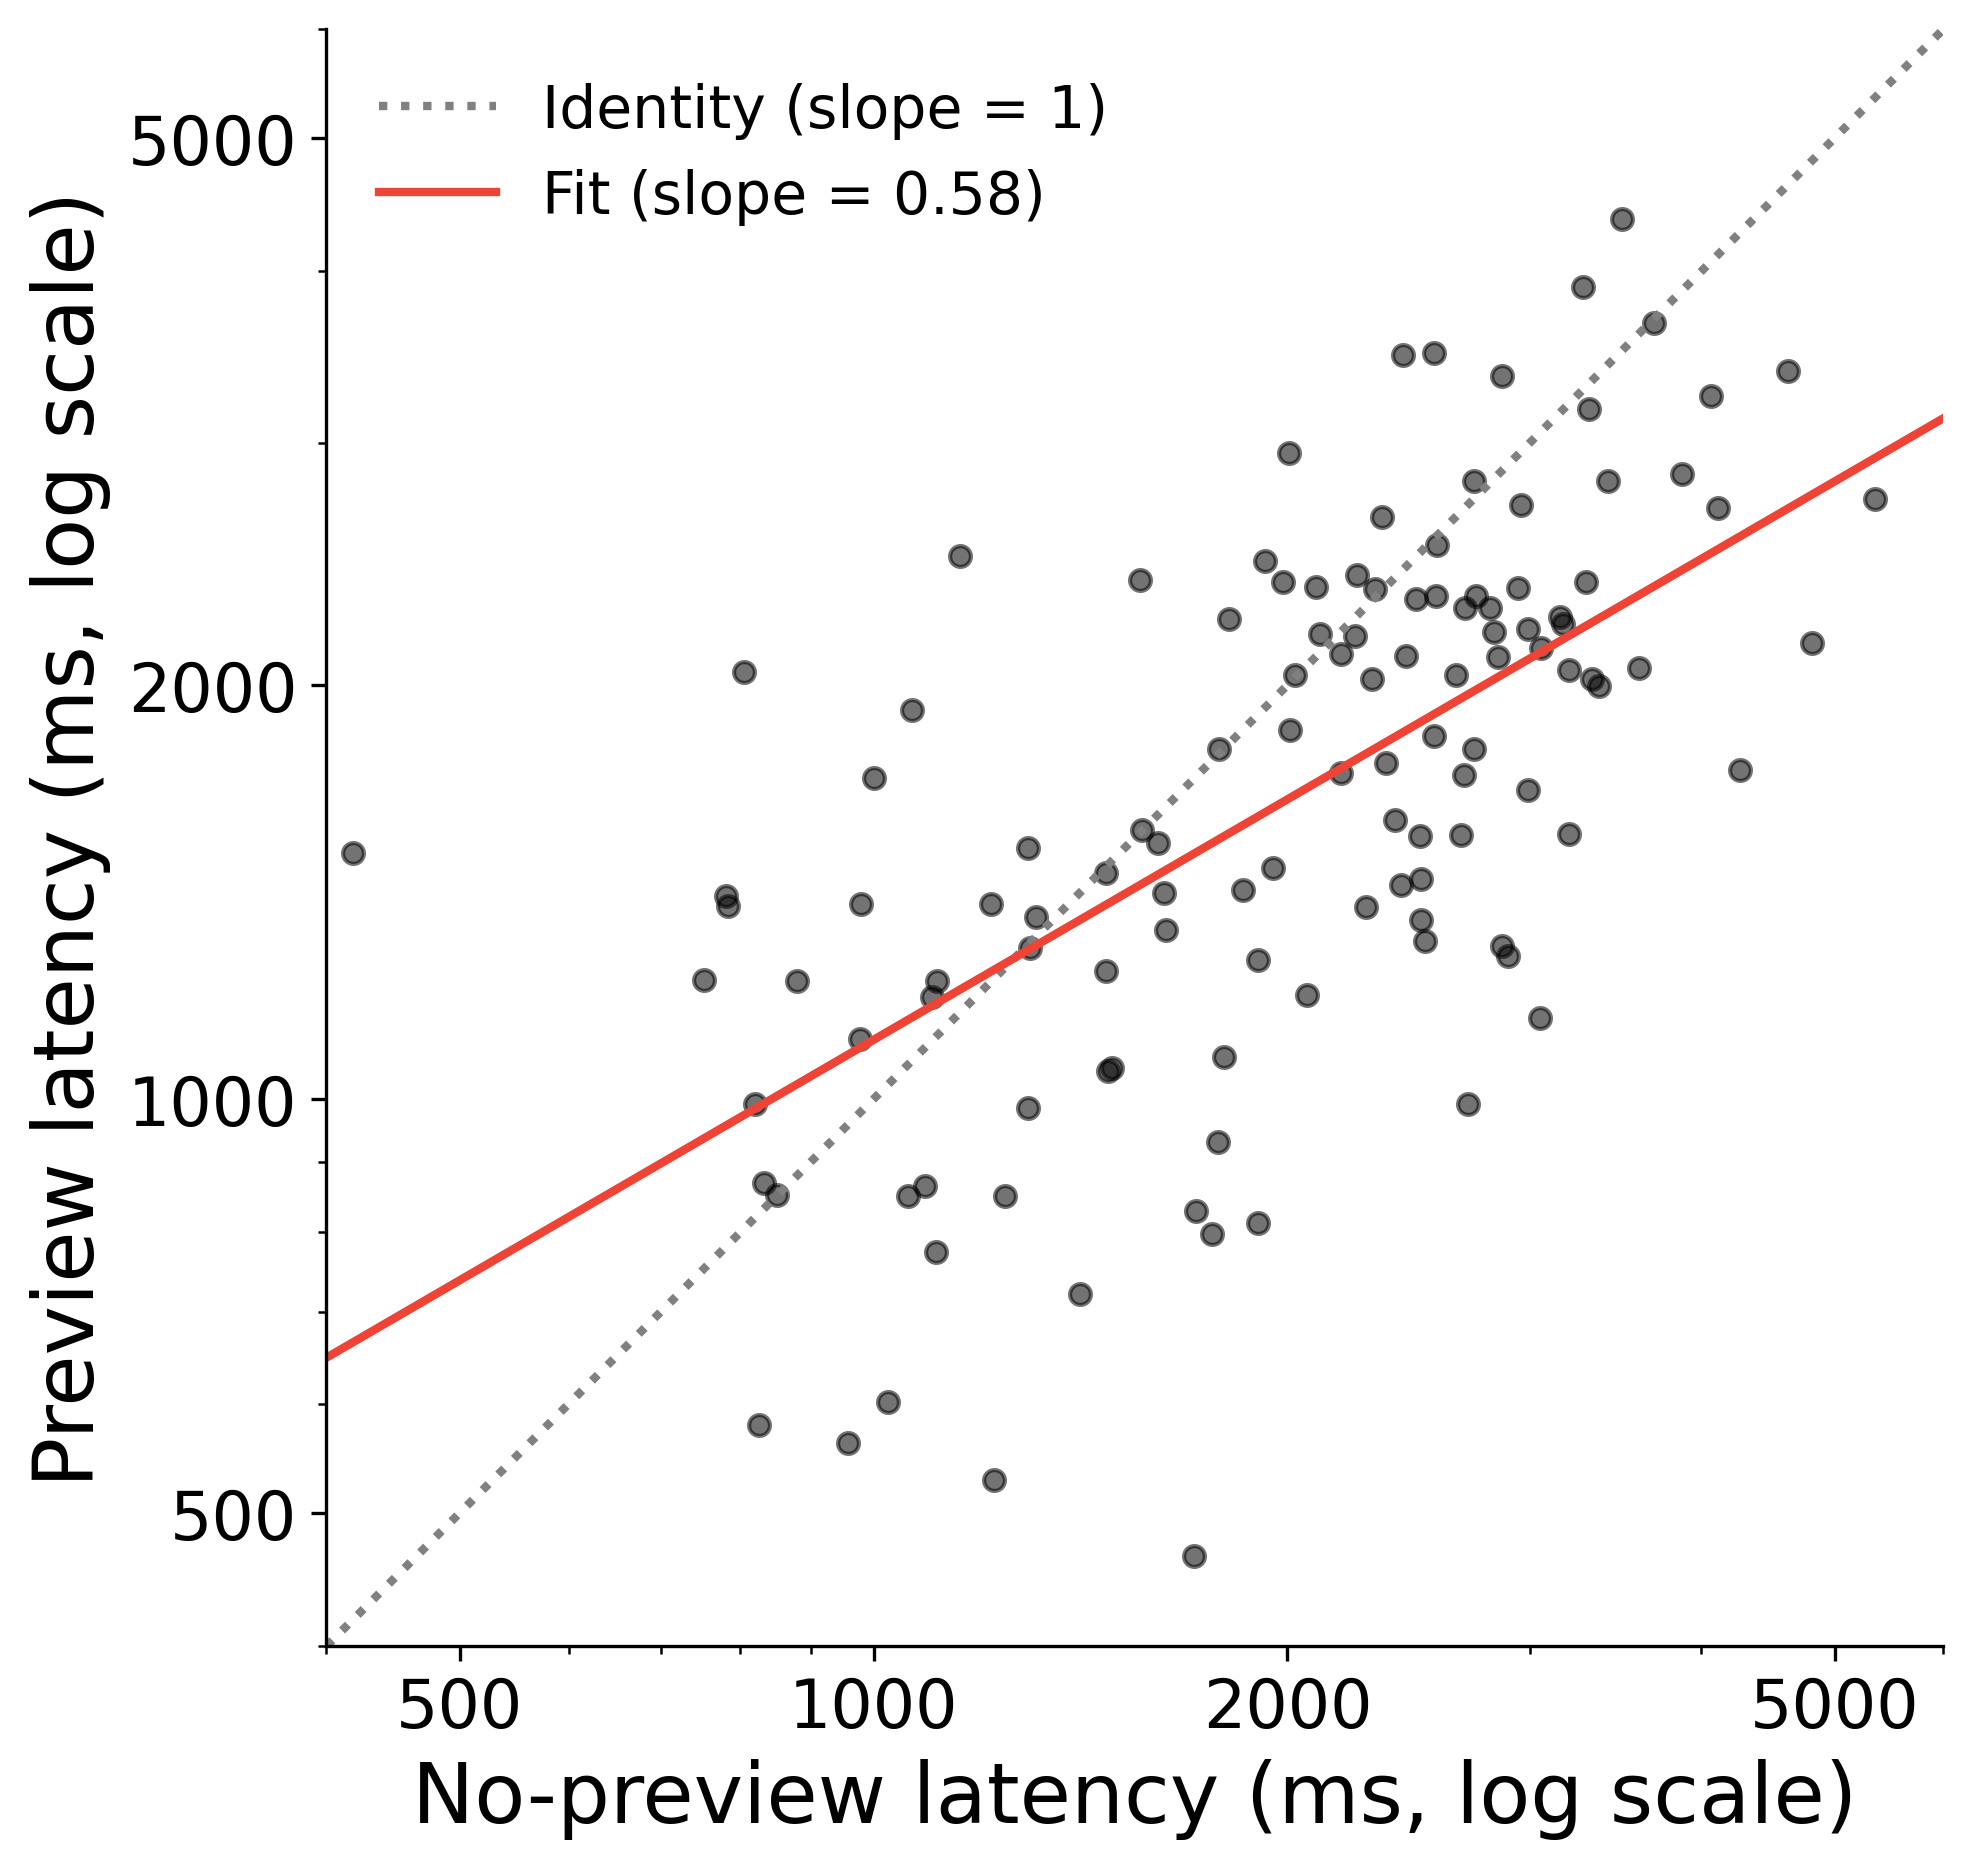

Moving-window task   n = 120 images, log-scale geometric means
  R2        0.378      ceiling 0.745
  slope     0.581, 95% CI [0.438, 0.746]
  p(slope >= 1)                    9.999e-05
  attenuation benchmark            0.887  (a true slope of 1 reads as this)
  p(slope >= benchmark)            0.0003
  disattenuated slope              0.655
  images below the identity line   68 %


In [5]:
panel_scatter("movingwindow", "fig1e_scatter_moving_window.png",
              ticks=[500, 1000, 2000, 5000], lim=(400, 6000),
              minor=[400, 600, 700, 800, 900, 3000, 4000, 6000])